# Network Intrusion Data: Exploratory Analysis and a Baseline Detector

**Question:** What does attack traffic look like compared with normal traffic, which features separate them, and how well does a simple model detect attacks it has never seen?

**Data:** NSL-KDD (Tavallaee et al., 2009; Canadian Institute for Cybersecurity), the standard benchmark for intrusion detection research. Each row is one network connection described by 41 features, labelled *normal* or with an attack type. Official training set: 125,973 connections. Official test set: 22,544 connections, which includes attack types that never appear in training.

**Tools:** Python (pandas, matplotlib, scikit-learn).

This is the dataset family used in intrusion detection research like my MSc dissertation topic (hybrid anomaly detection plus supervised learning). This notebook is a standalone exploratory analysis, not the dissertation itself.

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

BASE = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
for name in ["KDDTrain+.txt", "KDDTest+.txt"]:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(BASE + name.replace("+", "%2B"), f"data/{name}")

COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
    "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]
train = pd.read_csv("data/KDDTrain+.txt", names=COLUMNS)
test = pd.read_csv("data/KDDTest+.txt", names=COLUMNS)
print(train.shape, test.shape)

(125973, 43) (22544, 43)


## 1. Label attacks by category

The 39 attack types fall into four standard categories: **DoS** (denial of service), **Probe** (scanning), **R2L** (remote-to-local: unauthorised access from outside) and **U2R** (user-to-root: privilege escalation).

In [2]:
CATEGORY = {
    "DoS": ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"],
    "Probe": ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"],
    "R2L": ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock",
            "xsnoop", "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"],
    "U2R": ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"],
}
to_cat = {"normal": "Normal", **{a: c for c, attacks in CATEGORY.items() for a in attacks}}
for d in (train, test):
    d["category"] = d["label"].map(to_cat)
    d["is_attack"] = (d["label"] != "normal").astype(int)
assert train["category"].notna().all() and test["category"].notna().all()

unseen = sorted(set(test["label"]) - set(train["label"]))
unseen_share = test["label"].isin(unseen).mean()
print(f"Attack types only in the test set ({len(unseen)}): {unseen}")
print(f"Share of test connections that are unseen attack types: {unseen_share:.1%}")

Attack types only in the test set (17): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Share of test connections that are unseen attack types: 16.6%


## 2. Data quality

In [3]:
quality = pd.Series({
    "missing values (train)": int(train.isna().sum().sum()),
    "missing values (test)": int(test.isna().sum().sum()),
    "duplicate rows (train)": int(train.duplicated().sum()),
    "constant columns (train)": ", ".join(c for c in COLUMNS[:-2] if train[c].nunique() == 1),
    "services in test not in train": ", ".join(sorted(set(test["service"]) - set(train["service"]))) or "none",
})
quality

missing values (train)                           0
missing values (test)                            0
duplicate rows (train)                           0
constant columns (train)         num_outbound_cmds
services in test not in train                 none
dtype: object

## 3. Class balance: training versus test

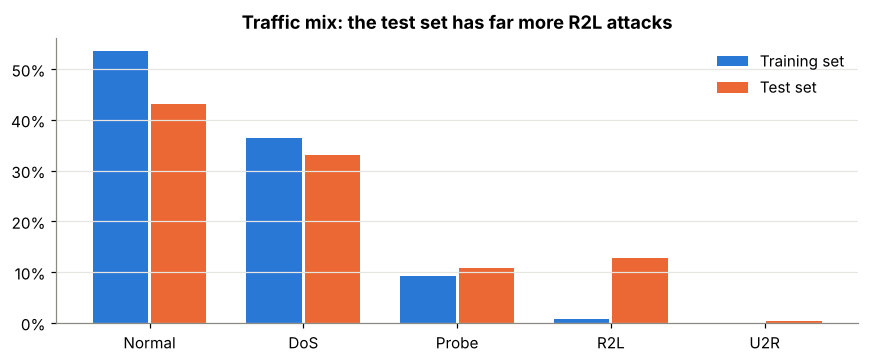

,train_pct,test_pct,train_n,test_n
category,,,,
Normal,53.458,43.076,67343,9711
DoS,36.458,33.091,45927,7460
Probe,9.253,10.739,11656,2421
R2L,0.790,12.797,995,2885
U2R,0.041,0.297,52,67


In [4]:
order = ["Normal", "DoS", "Probe", "R2L", "U2R"]
balance = pd.DataFrame({
    "train_pct": train["category"].value_counts(normalize=True).reindex(order) * 100,
    "test_pct": test["category"].value_counts(normalize=True).reindex(order) * 100,
    "train_n": train["category"].value_counts().reindex(order),
    "test_n": test["category"].value_counts().reindex(order),
})

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(order))
ax.bar(x - 0.19, balance["train_pct"], width=0.36, color=BLUE, label="Training set")
ax.bar(x + 0.19, balance["test_pct"], width=0.36, color=ORANGE, label="Test set")
ax.set_xticks(x); ax.set_xticklabels(order); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Traffic mix: the test set has far more R2L attacks"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("images/class_balance.png"); plt.show()
balance

## 4. Where attacks happen: protocol, service and connection flag

In [5]:
by_protocol = train.groupby("protocol_type")["is_attack"].agg(connections="size", attack_rate="mean")
by_flag = train.groupby("flag")["is_attack"].agg(connections="size", attack_rate="mean").sort_values("connections", ascending=False).head(6)
by_service = (train.groupby("service")["is_attack"].agg(connections="size", attack_rate="mean")
                   .query("connections >= 1000").sort_values("attack_rate", ascending=False))
display(by_protocol, by_flag, by_service.head(8))
s0 = by_flag.loc["S0"]
print(f"S0 (connection attempt with no reply): {int(s0.connections):,} connections, {s0.attack_rate:.1%} attacks")

,connections,attack_rate
protocol_type,,
icmp,8291,0.842
tcp,102689,0.478
udp,14993,0.171


,connections,attack_rate
flag,,
SF,74945,0.154
S0,34851,0.990
REJ,11233,0.760
RSTR,2421,0.940
RSTO,1562,0.860
S1,365,0.011


,connections,attack_rate
service,,
private,21853,0.955
ecr_i,3077,0.938
eco_i,4586,0.892
finger,1767,0.692
telnet,2353,0.610
ftp,1754,0.477
other,4359,0.403
ftp_data,6860,0.273


S0 (connection attempt with no reply): 34,851 connections, 99.0% attacks


## 5. Which features separate attacks from normal traffic?

Mutual information measures how much knowing a feature reduces uncertainty about whether a connection is an attack. It captures non-linear relationships, which matters here because many features are rates bunched at 0 or 1.

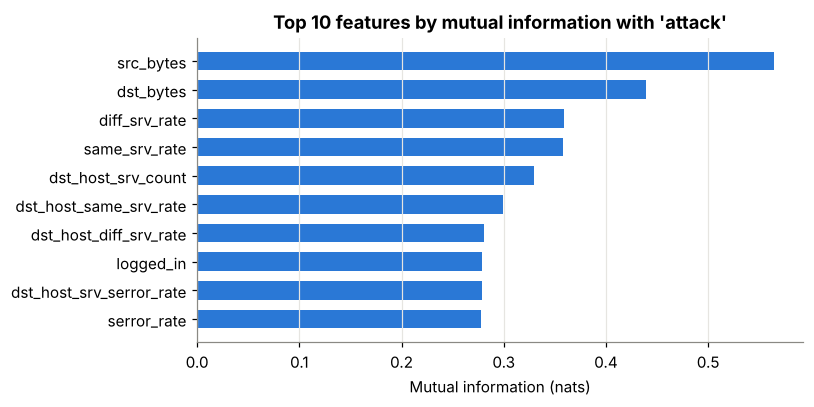

,same_srv_rate,dst_host_srv_count,serror_rate,logged_in,src_bytes
category,,,,,
Normal,1.000,255.000,0.000,1.000,233.000
DoS,0.070,13.000,1.000,0.000,0.000
Probe,1.000,2.000,0.000,0.000,1.000
R2L,1.000,35.000,0.000,1.000,334.000
U2R,1.000,2.500,0.000,1.000,273.000


In [6]:
numeric = [c for c in COLUMNS[:-2] if c not in ("protocol_type", "service", "flag") and train[c].nunique() > 1]
sample = train.sample(40_000, random_state=42)
mi = pd.Series(mutual_info_classif(sample[numeric], sample["is_attack"], random_state=42), index=numeric).sort_values(ascending=False)
top_mi = mi.head(10)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(top_mi.index[::-1], top_mi.values[::-1], color=BLUE, height=0.65)
ax.set_title("Top 10 features by mutual information with 'attack'"); ax.set_xlabel("Mutual information (nats)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("images/feature_mi.png"); plt.show()

compare = train.groupby("category")[["same_srv_rate", "dst_host_srv_count", "serror_rate", "logged_in", "src_bytes"]].median().reindex(order)
compare

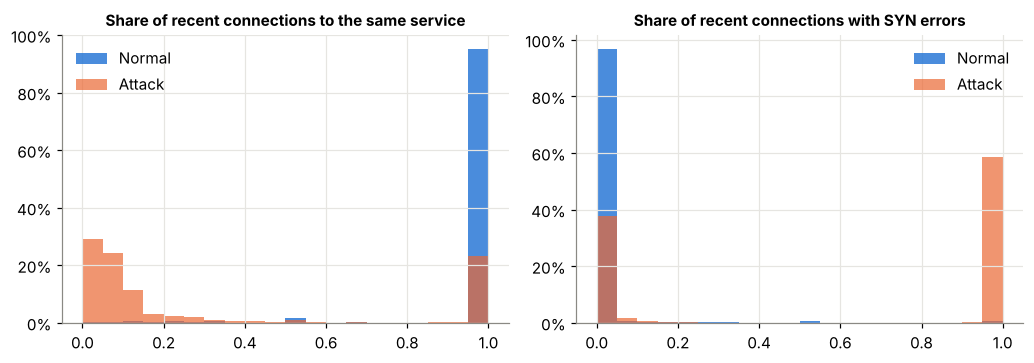

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, col, title in [(axes[0], "same_srv_rate", "Share of recent connections to the same service"),
                        (axes[1], "serror_rate", "Share of recent connections with SYN errors")]:
    bins = np.linspace(0, 1, 21)
    ax.hist(train.loc[train["is_attack"] == 0, col], bins=bins, color=BLUE, alpha=0.85, label="Normal", weights=np.full((train["is_attack"] == 0).sum(), 100 / (train["is_attack"] == 0).sum()))
    ax.hist(train.loc[train["is_attack"] == 1, col], bins=bins, color=ORANGE, alpha=0.7, label="Attack", weights=np.full((train["is_attack"] == 1).sum(), 100 / (train["is_attack"] == 1).sum()))
    ax.set_title(title, fontsize=10); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("images/feature_distributions.png"); plt.show()

## 6. Baseline detector: why the evaluation split matters

A random forest is trained on the official training set. It is scored two ways: with 5-fold cross-validation inside the training set, and on the official test set, which contains new attack types.

In [8]:
X_train = pd.get_dummies(train[COLUMNS[:-2]], columns=["protocol_type", "service", "flag"], dtype=int)
X_test = pd.get_dummies(test[COLUMNS[:-2]], columns=["protocol_type", "service", "flag"], dtype=int).reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = train["is_attack"], test["is_attack"]

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
cv = cross_val_score(model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy", n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

scores = {
    "cv_accuracy_pct": round(100 * cv.mean(), 2),
    "test_accuracy_pct": round(100 * accuracy_score(y_test, pred), 2),
    "test_attack_recall_pct": round(100 * recall_score(y_test, pred), 2),
    "test_attack_precision_pct": round(100 * precision_score(y_test, pred), 2),
    "test_false_alarm_rate_pct": round(100 * ((pred == 1) & (y_test == 0)).sum() / (y_test == 0).sum(), 2),
}
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(scores); print(f"confusion: TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")

{'cv_accuracy_pct': np.float64(99.88), 'test_accuracy_pct': 76.5, 'test_attack_recall_pct': 60.8, 'test_attack_precision_pct': 96.7, 'test_false_alarm_rate_pct': np.float64(2.74)}
confusion: TN=9,445 FP=266 FN=5,031 TP=7,802


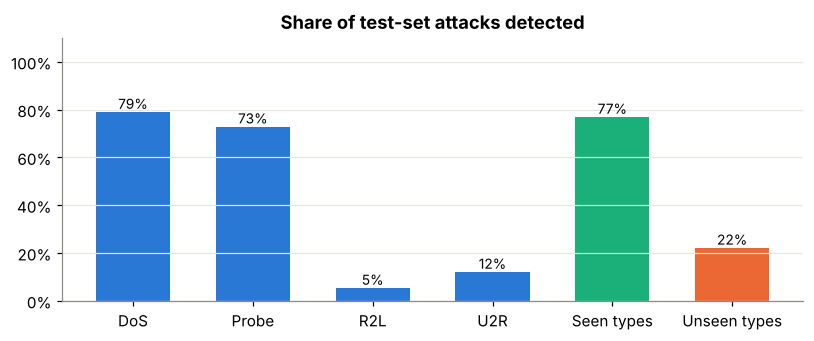

{'DoS': 78.8, 'Probe': 72.7, 'R2L': 5.2, 'U2R': 11.9} 76.8 22.0


In [9]:
test_eval = test.assign(pred=pred, seen=~test["label"].isin(unseen))
recall_by_cat = (test_eval[test_eval["is_attack"] == 1].groupby("category")["pred"].mean() * 100).reindex(order[1:])
recall_seen = test_eval[(test_eval["is_attack"] == 1) & test_eval["seen"]]["pred"].mean() * 100
recall_unseen = test_eval[(test_eval["is_attack"] == 1) & ~test_eval["seen"]]["pred"].mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.2))
labels = list(recall_by_cat.index) + ["Seen types", "Unseen types"]
vals = list(recall_by_cat.values) + [recall_seen, recall_unseen]
colors = [BLUE] * len(recall_by_cat) + [AQUA, ORANGE]
ax.bar(labels, vals, color=colors, width=0.62)
for i, v in enumerate(vals):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_ylim(0, 110); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="x", visible=False)
ax.set_title("Share of test-set attacks detected")
fig.tight_layout(); fig.savefig("images/detection_by_category.png"); plt.show()
print(recall_by_cat.round(1).to_dict(), round(recall_seen, 1), round(recall_unseen, 1))

## Findings

1. **The test set is a different problem from the training set.** R2L attacks are 0.8% of training traffic but 12.8% of test traffic, and 16.6% of test connections are attack types the model never sees in training (17 new types).
2. **Some signals are almost decisive on their own.** 99.0% of the 34,851 connections flagged `S0` (an attempt that got no reply) are attacks, and 84% of ICMP traffic is attack traffic, mostly floods and scans.
3. **DoS traffic looks like a burst of half-open connections.** The median DoS connection sends 0 bytes, has a SYN error rate of 1.0 and only 7% of recent connections go to the same service. Normal traffic is the opposite: logged in, same service, no errors.
4. **R2L and U2R attacks look like normal sessions.** Their medians match normal traffic on most features (logged in, same service, no errors), which is why they are hard to catch.
5. **Cross-validation accuracy is misleading here.** The random forest scores 99.88% in 5-fold cross-validation but 76.5% on the official test set. It catches 60.8% of test attacks, with a 2.7% false alarm rate on normal traffic.
6. **The model misses what it has not seen.** It detects 76.8% of attacks of known types but only 22.0% of new types, and just 5.2% of R2L attacks.

**What this means for a detector.** A supervised model alone learns the attacks in its training data. Catching new attacks needs an anomaly-detection component that flags traffic unlike normal behaviour, which is the case for the hybrid approach in my dissertation topic.

**Limitations.** NSL-KDD is derived from 1998 simulated traffic, so it is a benchmark rather than a picture of today's networks. The baseline uses default random forest settings with no tuning.

In [10]:
summary = {
    "train_rows": len(train), "test_rows": len(test), "features": 41,
    "unseen_types": unseen, "unseen_share_pct": round(100 * unseen_share, 1),
    "quality": {k: str(v) for k, v in quality.items()},
    "balance": [{"category": c, **{k: (round(float(v), 1) if "pct" in k else int(v)) for k, v in row.items()}} for c, row in balance.iterrows()],
    "attack_rate_by_protocol": {k: round(100 * float(v), 1) for k, v in by_protocol["attack_rate"].items()},
    "s0": {"connections": int(s0.connections), "attack_rate_pct": round(100 * float(s0.attack_rate), 1)},
    "top_mi": [{"feature": k, "mi": round(float(v), 3)} for k, v in top_mi.items()],
    "scores": scores,
    "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "recall_by_category_pct": {k: round(float(v), 1) for k, v in recall_by_cat.items()},
    "recall_seen_pct": round(float(recall_seen), 1), "recall_unseen_pct": round(float(recall_unseen), 1),
    "attack_share_train_pct": round(100 * train["is_attack"].mean(), 1), "attack_share_test_pct": round(100 * test["is_attack"].mean(), 1),
}
json.dump(summary, open("results/summary.json", "w"), indent=1)
print("saved results/summary.json")

saved results/summary.json
